In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [11]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [12]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [13]:
df['TotalCharges'].dtype

dtype('float64')

In [14]:
df.dropna(subset=['TotalCharges'], inplace=True)

In [15]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
df.shape

(7032, 21)

In [17]:
df['Churn'].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [18]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

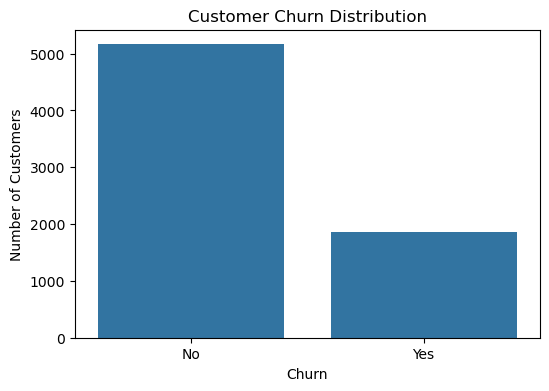

In [19]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

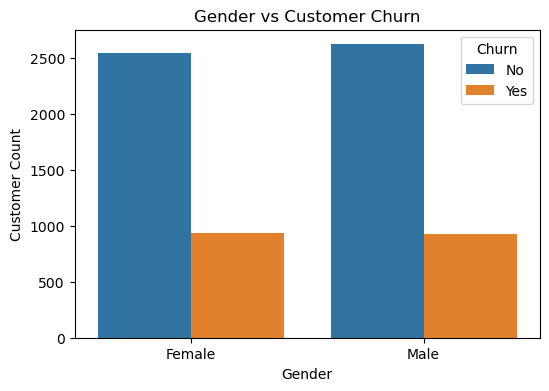

In [20]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='gender', hue='Churn')

plt.title('Gender vs Customer Churn')
plt.xlabel('Gender')
plt.ylabel('Customer Count')

plt.show()

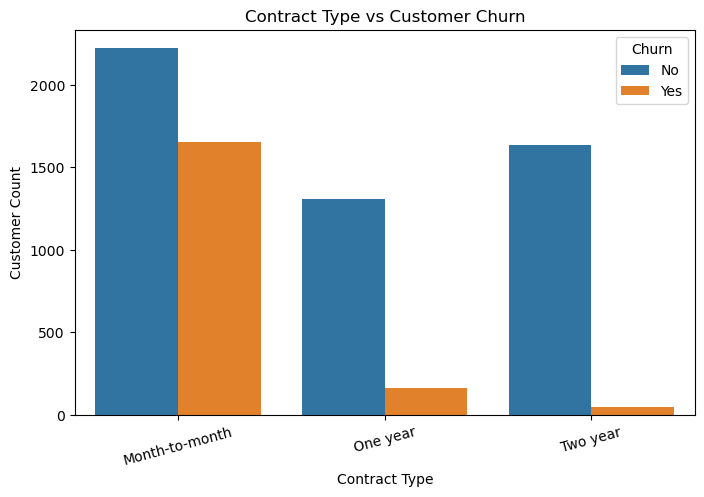

In [21]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Contract Type vs Customer Churn')
plt.xlabel('Contract Type')
plt.ylabel('Customer Count')

plt.xticks(rotation=15)
plt.show()

In [22]:
pd.crosstab(df['gender'], df['Churn'])

Churn,No,Yes
gender,,
Female,2544,939
Male,2619,930


In [23]:
pd.crosstab(df['Contract'], df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


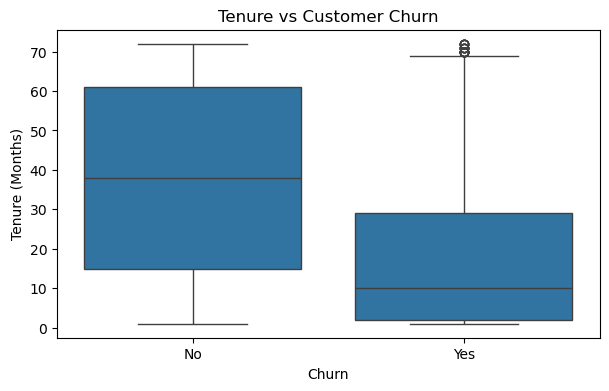

In [24]:
plt.figure(figsize=(7,4))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title('Tenure vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.show()

In [25]:
df.groupby('Churn')['tenure'].mean()

Churn
No     37.650010
Yes    17.979133
Name: tenure, dtype: float64

In [26]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64

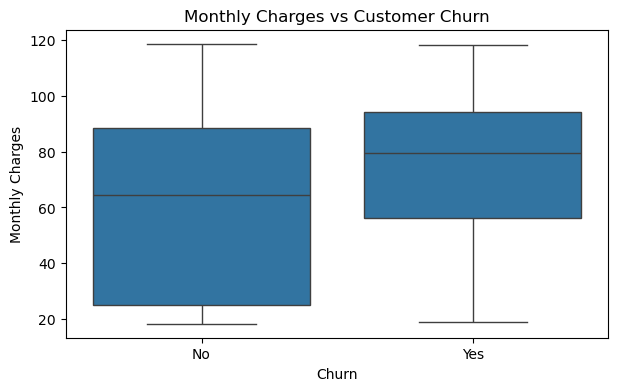

In [27]:
plt.figure(figsize=(7,4))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

In [28]:
pd.crosstab(df['InternetService'], df['Churn'])

Churn,No,Yes
InternetService,,
DSL,1957,459
Fiber optic,1799,1297
No,1407,113


In [29]:
pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
InternetService,,
DSL,81.001656,18.998344
Fiber optic,58.107235,41.892765
No,92.565789,7.434211


In [30]:
pd.crosstab(df['PaymentMethod'], df['Churn'])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1284,258
Credit card (automatic),1289,232
Electronic check,1294,1071
Mailed check,1296,308


In [31]:
pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.268482,16.731518
Credit card (automatic),84.746877,15.253123
Electronic check,54.714588,45.285412
Mailed check,80.798005,19.201995


In [32]:
df.drop('customerID', axis=1, inplace=True)

In [33]:
df.shape

(7032, 20)

In [34]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [35]:
df['Churn'].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [36]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [37]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (7032, 19)
y Shape: (7032,)


In [39]:
X = df.drop('Churn', axis=1)
y = df['Churn']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (7032, 19)
y Shape: (7032,)


In [40]:
categorical_cols = X.select_dtypes(include='object').columns

numerical_cols = X.select_dtypes(exclude='object').columns

print("Categorical Columns:")
print(list(categorical_cols))

print("\nNumerical Columns:")
print(list(numerical_cols))

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 19)
X_test: (1407, 19)
y_train: (5625,)
y_test: (1407,)


In [42]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [43]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

In [44]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape)
print("X_test_processed:", X_test_processed.shape)

X_train_processed: (5625, 45)
X_test_processed: (1407, 45)


In [45]:
from sklearn.linear_model import LogisticRegression

In [46]:
lr_model = LogisticRegression(random_state=42)

In [47]:
lr_model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [48]:
y_pred_lr = lr_model.predict(X_test_processed)

In [49]:
print("Predictions:", y_pred_lr[:10])
print("Actual Values:", y_test.values[:10])

Predictions: [0 1 0 0 0 0 0 0 1 0]
Actual Values: [0 0 0 1 0 1 0 0 1 0]


In [50]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [51]:
accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Logistic Regression Accuracy: 0.8038379530916845
Accuracy Percentage: 80.38379530916845


In [52]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



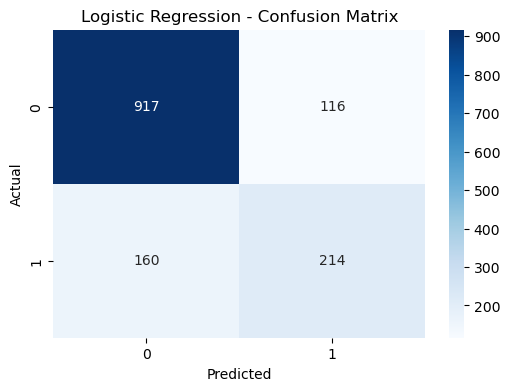

In [53]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [54]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train_processed, y_train)

y_pred_rf = rf_model.predict(X_test_processed)

In [55]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Accuracy Percentage:", accuracy_rf * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.7789623312011372
Accuracy Percentage: 77.89623312011372

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1033
           1       0.61      0.46      0.53       374

    accuracy                           0.78      1407
   macro avg       0.72      0.68      0.69      1407
weighted avg       0.77      0.78      0.77      1407



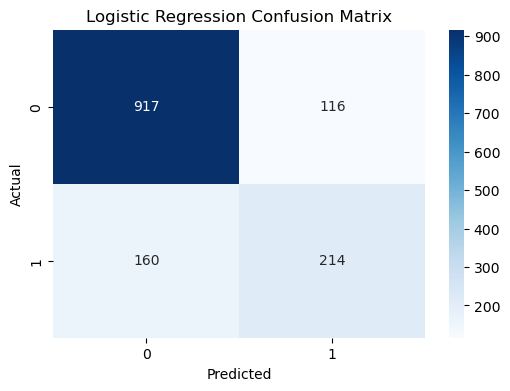

In [56]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [57]:
feature_names = preprocessor.get_feature_names_out()

coefficients = lr_model.coef_[0]

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': coefficients
})

feature_importance['Absolute_Importance'] = abs(
    feature_importance['Importance']
)

feature_importance = feature_importance.sort_values(
    by='Absolute_Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance,Absolute_Importance
42,num__tenure,-1.352313,1.352313
34,cat__Contract_Two year,-0.779030,0.779030
44,num__TotalCharges,0.644014,0.644014
11,cat__InternetService_DSL,-0.616132,0.616132
32,cat__Contract_Month-to-month,0.613846,0.613846
12,cat__InternetService_Fiber optic,0.590184,0.590184
43,num__MonthlyCharges,-0.541006,0.541006
35,cat__PaperlessBilling_No,-0.300387,0.300387
8,cat__MultipleLines_No,-0.293470,0.293470
30,cat__StreamingMovies_No internet service,-0.283724,0.283724


In [59]:
lr_balanced = LogisticRegression(
    random_state=42,
    class_weight='balanced',
    max_iter=1000
)

lr_balanced.fit(X_train_processed, y_train)

y_pred_balanced = lr_balanced.predict(X_test_processed)

In [60]:
print("Balanced Logistic Regression Results:")

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Balanced Logistic Regression Results:
Accuracy: 0.7256574271499645

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [63]:
print("Balanced Logistic Regression Results:")

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Balanced Logistic Regression Results:
Accuracy: 0.7256574271499645

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



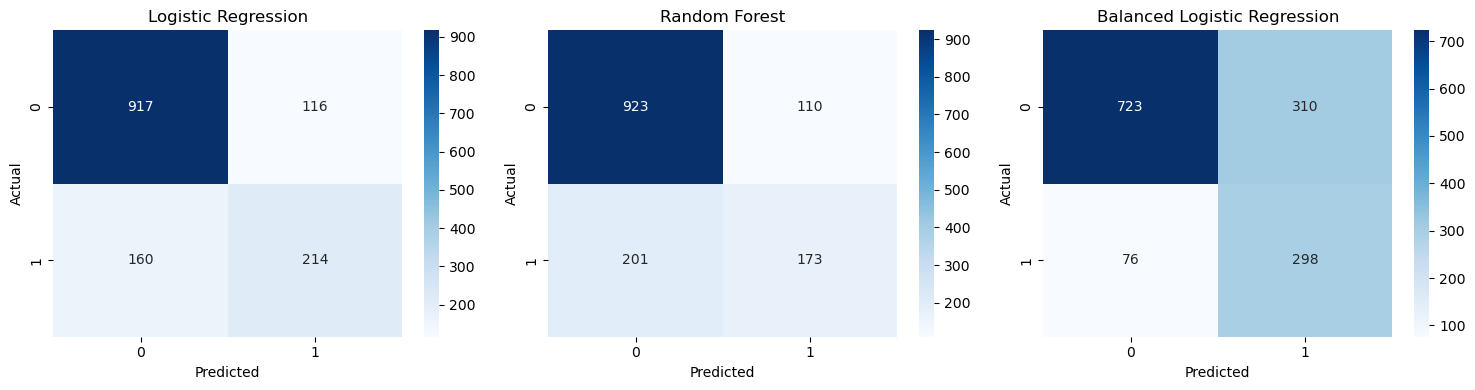

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models = [
    (y_pred_lr, "Logistic Regression"),
    (y_pred_rf, "Random Forest"),
    (y_pred_balanced, "Balanced Logistic Regression")
]

for ax, (pred, name) in zip(axes, models):
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


# Customer Churn Prediction

## Project Overview
Built a Machine Learning model to predict whether a telecom customer is likely to leave the company.

## Dataset
- Total Records: 7,032
- Features: 19
- Target Variable: Churn

## Steps Performed
1. Data Cleaning
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. One-Hot Encoding
5. Feature Scaling
6. Model Building
7. Model Evaluation
8. Feature Importance Analysis

## Models Used
- Logistic Regression
- Random Forest
- Balanced Logistic Regression

## Model Results
- Logistic Regression Accuracy: 80.38%
- Random Forest Accuracy: 77.90%
- Balanced Logistic Regression Accuracy: 72.57%
- Balanced Logistic Regression Churn Recall: 80%

## Key Business Insights
- Month-to-month contract customers show higher churn.
- Customers with shorter tenure are more likely to churn.
- Fiber optic users show higher churn.
- Electronic check users show higher churn.

## Conclusion
Logistic Regression achieved the highest accuracy, while Balanced Logistic Regression achieved the highest churn recall. The project demonstrates how machine learning can help businesses identify customers at risk of leaving.
